# Spotify Track Popularity Analysis

**Predicting what drives song popularity from audio features and genre**

| | |
|---|---|
| **Dataset** | [Spotify Tracks Dataset](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset) (Kaggle) |
| **Task** | Exploratory data analysis and supervised regression |
| **Target variable** | `popularity` (integer score, 0–100) |
| **Tools** | Python 3.12, pandas, NumPy, Matplotlib, seaborn, scikit-learn |

---

## Table of Contents

0. [Project Overview](#0.-Project-Overview)
1. [Environment Setup](#1.-Environment-Setup)
2. [Data Loading & Initial Inspection](#2.-Data-Loading-&-Initial-Inspection)
3. [Data Cleaning](#3.-Data-Cleaning)
4. [Exploratory Data Analysis](#4.-Exploratory-Data-Analysis)
5. [Modeling](#5.-Modeling)
6. [Error Analysis](#6.-Error-Analysis)
7. [Model Persistence](#7.-Model-Persistence)
8. [Conclusions, Limitations & Next Steps](#8.-Conclusions,-Limitations-&-Next-Steps)

## 0. Project Overview

### Objective
This project analyzes roughly **90,000 unique Spotify tracks** to answer one question: *what actually drives a song's popularity?* It then builds a regression model that predicts the popularity score and quantifies how much each type of information (audio features vs. genre) contributes.

### Approach
1. **Inspect and clean** the raw data (missing values, duplicate tracks, physically implausible values).
2. **Explore** distributions and relationships between audio features and popularity.
3. **Model** popularity with an incremental set of models, from a naive baseline up to a Random Forest, so the value of each addition is measurable.
4. **Diagnose** the model by studying its worst predictions.
5. **Persist** the trained model for use by a deployment API (`app.py`).

### Key Finding
> **Genre explains popularity far better than any individual audio feature.** Audio characteristics alone (danceability, tempo, energy, etc.) are weak predictors, while average popularity varies by roughly **57 points** across genres on a 0–100 scale.

## 1. Environment Setup

### Dependencies
Package installation is intentionally kept out of the notebook so that it stays reproducible and free of side effects. Install the dependencies once, in the project environment, before running:

```bash
uv pip install pandas numpy seaborn matplotlib scikit-learn joblib
```

### Imports and Global Configuration
All imports, plotting defaults, file paths, and the random seed are defined in one place. Using a single `RANDOM_STATE` and a shared colour palette keeps results reproducible and figures visually consistent.

In [48]:
!uv pip install pandas numpy seaborn matplotlib scikit-learn joblib

Using Python 3.12.15 environment at: C:\Users\muham\OneDrive\Desktop\Mosid Khan\.venv
Checked 6 packages in 18ms


In [49]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)

# ── Configuration ──────────────────────────────────────────────
RANDOM_STATE = 42
DATA_PATH    = Path("dataset.csv")
FIGURE_DIR   = Path("figures")
MODEL_PATH   = Path("popularity_model.pkl")
GENRE_PATH   = Path("genre_means.pkl")

PRIMARY   = "#8A2BE2"   # strong purple: primary series / "top" groups
SECONDARY = "#C8A2C8"   # light purple: secondary series / "bottom" groups

FIGURE_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Data Loading & Initial Inspection

The dataset contains **114,000 rows and 21 columns**. Before any cleaning, we check its shape, columns, and data types to confirm it loaded correctly.

### Data Dictionary

| Column | Type | Description |
|---|---|---|
| `Unnamed: 0` | int | Leftover row index from the CSV export (no analytical value) |
| `track_id` | str | Unique Spotify identifier of the track |
| `artists`, `album_name`, `track_name` | str | Track metadata (multiple artists are separated by `;`) |
| `popularity` | int | **Target.** Spotify popularity score, 0–100, based on recent play counts |
| `duration_ms` | int | Track length in milliseconds |
| `explicit` | bool | Whether the track has explicit lyrics |
| `danceability` | float | Suitability for dancing, 0.0–1.0 |
| `energy` | float | Perceived intensity and activity, 0.0–1.0 |
| `key` | int | Pitch class of the track (0 = C, 1 = C♯, …, 11 = B) |
| `loudness` | float | Overall loudness in dB |
| `mode` | int | Modality: 1 = major, 0 = minor |
| `speechiness` | float | Presence of spoken words, 0.0–1.0 |
| `acousticness` | float | Confidence the track is acoustic, 0.0–1.0 |
| `instrumentalness` | float | Likelihood the track has no vocals, 0.0–1.0 |
| `liveness` | float | Probability the track was performed live, 0.0–1.0 |
| `valence` | float | Musical positiveness (happy vs. sad), 0.0–1.0 |
| `tempo` | float | Estimated tempo in beats per minute (BPM) |
| `time_signature` | int | Estimated beats per bar |
| `track_genre` | str | Genre tag under which the track was collected |

In [50]:
df = pd.read_csv("dataset.csv")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

Shape: 114,000 rows × 21 columns


In [51]:
print(df.columns.tolist())

['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [52]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 3. Data Cleaning

Cleaning is done in four steps, each followed by a verification: **(3.1)** missing values, **(3.2)** duplicate tracks, **(3.3)** physically implausible values (`tempo`), and **(3.4)** duration outliers.

### 3.1 Missing Values
We first count missing values per column to decide whether imputation or row removal is appropriate.

In [53]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Only three rows have missing values, all in the text fields `artists`, `album_name`, and `track_name` (one missing entry each). Because this is a negligible fraction of the 114,000 rows and the affected fields cannot be sensibly imputed, these rows are **dropped**.

In [54]:
df = df.dropna(subset=["artists", "album_name", "track_name"])
print(f"Rows after dropping missing values: {len(df):,}")

Rows after dropping missing values: 113,999


### 3.2 Duplicate Tracks

A song can legitimately appear under **multiple genres**, which produces repeated `track_id` values with different `track_genre` tags. Before deciding how to deal with them, we measure how widespread duplication is, using both `track_id` and the (`track_name`, `artists`) combination.

In [55]:
print(f"Total rows before de-duplication : {len(df):,}")
print(f"Duplicate track_ids              : {df.duplicated(subset=['track_id']).sum():,}")
print(f"Duplicate track + artist combos  : {df.duplicated(subset=['track_name', 'artists']).sum():,}")

Total rows before de-duplication : 113,999
Duplicate track_ids              : 24,259
Duplicate track + artist combos  : 32,656


Inspecting a few duplicated `track_id`s confirms that the rows are the **same track repeated under different genre tags**, rather than data-entry errors.

In [56]:
duplicated_tracks = df[df.duplicated(subset="track_id", keep=False)].sort_values("track_id")
duplicated_tracks[["track_id", "track_name", "artists", "popularity", "track_genre"]].head(10)

,track_id,track_name,artists,popularity,track_genre
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,0,chill
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,0,soul
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,38,punk-rock
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,38,ska
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,86,rock
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,86,alternative
2106,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,86,alt-rock
33178,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,58,emo
94239,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,58,sad
97533,006rHBBNLJMpQs8fRC2GDe,Agora Estou Sofrendo - Ao Vivo,Calcinha Preta;Gusttavo Lima,47,sertanejo


**Decision:** keep one row per `track_id` so that each song is counted once. This prevents the same track from appearing in both the training and test sets (data leakage) and avoids over-weighting multi-genre songs.

> ⚠️ **Known limitation:** `keep="first"` retains an *arbitrary* genre tag for each track. The consequences of this choice surface later in the [Error Analysis](#6.-Error-Analysis) and are discussed in the conclusions.

In [57]:
df_unique = df.drop_duplicates(subset="track_id", keep="first").copy()

print(f"Full dataset  : {len(df):,} rows")
print(f"Unique tracks : {len(df_unique):,} rows")
print(f"Rows removed  : {len(df) - len(df_unique):,}")

Full dataset  : 113,999 rows
Unique tracks : 89,740 rows
Rows removed  : 24,259


In [58]:
df_unique.dtypes

Unnamed: 0            int64
track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object

In [59]:
df_unique[["duration_ms", "tempo", "popularity"]].describe()

,duration_ms,tempo,popularity
count,8.974000e+04,89740.000000,89740.000000
mean,2.291444e+05,122.058134,33.198808
std,1.129458e+05,30.117651,20.580640
min,8.586000e+03,0.000000,0.000000
25%,1.730400e+05,99.262750,19.000000
50%,2.132955e+05,122.013000,33.000000
75%,2.642930e+05,140.077000,49.000000
max,5.237295e+06,243.372000,100.000000


### 3.3 Implausible Values: `tempo = 0`

The summary statistics show a minimum `tempo` of **0 BPM**, which is not physically meaningful for a song. We investigate how many tracks are affected and what they are before deciding how to treat them.

In [60]:
n_zero_tempo = (df_unique["tempo"] == 0).sum()
print(f"Tracks with tempo = 0: {n_zero_tempo}")
df_unique.loc[df_unique["tempo"] == 0, ["track_name", "artists", "tempo", "duration_ms"]].head(10)

Tracks with tempo = 0: 157


,track_name,artists,tempo,duration_ms
4131,The Departure,Max Richter;Lang Lang,0.0,151506
4379,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,0.0,73266
4664,Ferme Les Yeux,Sylvain Chauveau,0.0,68493
45670,Campomoro,Little Symphony,0.0,148711
45720,Ritornello,Little Symphony,0.0,102000
45729,Amager,Little Symphony,0.0,133624
45773,Ionian,Little Symphony,0.0,93125
59221,Yes! No! I Mean Yes! No I Don't!,Leila Bela,0.0,38333
59310,The Exorsism Begins...,Leila Bela,0.0,8586
59473,Leaving Her Quantum Journey Behind...,Leila Bela,0.0,50186


**Finding:** the `tempo = 0` tracks are genuine ambient and orchestral pieces (e.g. Max Richter, film scores) for which Spotify's beat-detection algorithm could not find a steady tempo. This is a **measurement gap, not bad data**.

**Decision:** convert `tempo = 0` to `NaN` rather than dropping the rows. This preserves the other valid features of each song. Rows with a missing `tempo` are excluded only at modeling time.

In [61]:
df_unique["tempo"] = df_unique["tempo"].replace(0, np.nan)

print(f"Tempo = 0 remaining     : {(df_unique['tempo'] == 0).sum()}")
print(f"Tempo missing (NaN)     : {df_unique['tempo'].isna().sum()}")

Tempo = 0 remaining     : 0
Tempo missing (NaN)     : 157


### 3.4 Duration Outliers

Extreme durations could also indicate data errors. We investigate tracks **shorter than 30 seconds** and **longer than 10 minutes**.

In [62]:
short_tracks = df_unique[df_unique["duration_ms"] < 30_000]
long_tracks  = df_unique[df_unique["duration_ms"] > 600_000]

print(f"Tracks under 30 seconds : {len(short_tracks)}")
print(f"Tracks over 10 minutes  : {len(long_tracks)}")

print("\n--- Under 30 seconds ---")
display(short_tracks[["track_name", "artists", "duration_ms"]].head(10))

print("--- Over 10 minutes ---")
display(long_tracks[["track_name", "artists", "duration_ms"]].head(10))

Tracks under 30 seconds : 14
Tracks over 10 minutes  : 550

--- Under 30 seconds ---


,track_name,artists,duration_ms
11398,"Cello Suite No. 3, Op. 87: IX. Passacaglia (Ex...",Benjamin Britten;Steven Isserlis,22266
16288,"Carnaval, Op. 9: No. 20, Pause (Live in Japan,...",Robert Schumann;Pavel Nersessian,17826
16292,"Carnaval, Op. 9: No. 13, Estrella (Live in Jap...",Robert Schumann;Pavel Nersessian,23506
16856,"Andante in C Major, K. 1a",Wolfgang Amadeus Mozart;Ingrid Haebler,17453
59306,V-7,Leila Bela,21120
59310,The Exorsism Begins...,Leila Bela,8586
59434,Aural Blue,Alireza Mashayekhi;Ata Ebtekar;The Iranian Orc...,24666
59458,V-3,Leila Bela,28026
59609,Shatter,Leila Bela,21240
59711,Breath Ritual,Leila Bela,28946


--- Over 10 minutes ---


,track_name,artists,duration_ms
1251,Dove,Cymande,655440
1505,Zombie,Fela Kuti,745653
1644,Qué Sabemos,Newen Afrobeat,625066
1688,Lady,Fela Kuti,828586
1820,Jealousy,Tony Allen With Africa 70,683893
1836,When The Going Is Smooth & Good,William Onyeabor,773800
1902,Expensive Shit,Fela Kuti;Afrika 70,793200
1980,Shuffering and Shmiling,Fela Kuti,745386
2646,Get Innocuous! - Soulwax Remix,LCD Soundsystem;Soulwax,601240
2768,Arriving Somewhere But Not Here,Porcupine Tree,722200


**Finding:** the short tracks are legitimate classical movements (e.g. Mozart, Schumann), and the long tracks are genuine Afrobeat and progressive-rock songs where extended runtimes are standard for the genre.

**Decision:** **keep both groups as-is.** No error was found; these are simply genres with different normal conventions.

### Cleaning Summary

| Step | Issue | Action | Result |
|---|---|---|---|
| 3.1 | 3 rows with missing text fields | Dropped | 113,999 rows |
| 3.2 | 24,259 duplicate `track_id`s (multi-genre tracks) | Kept first occurrence | 89,740 unique tracks |
| 3.3 | 157 tracks with `tempo = 0` | Converted to `NaN` | Rows preserved |
| 3.4 | Very short / very long tracks | None (valid data) | No change |

## 4. Exploratory Data Analysis

The EDA moves from simple to complex: **(4.1)** the target distribution and univariate feature distributions, **(4.2)** numeric relationships with popularity, **(4.3)** categorical comparisons, and **(4.4)** the role of genre.

### 4.1 Univariate Distributions

#### Target variable: `popularity`
The first plot shows how popularity scores are distributed across all unique tracks.

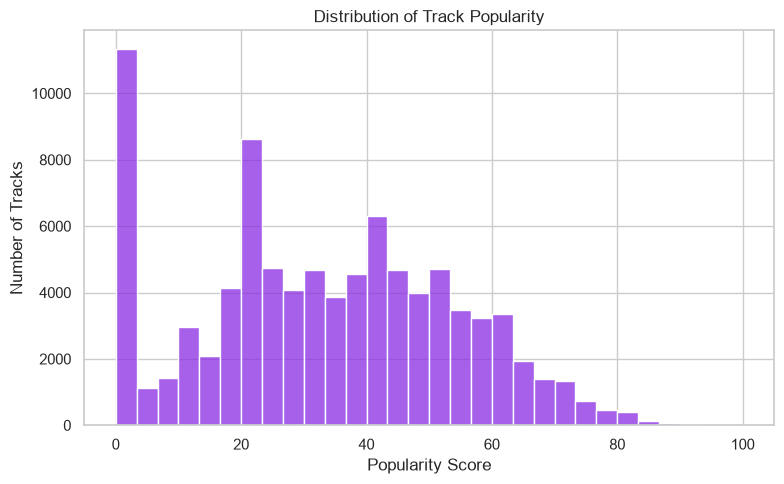

In [63]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df_unique["popularity"], bins=30, color=PRIMARY, ax=ax)
ax.set_xlabel("Popularity Score")
ax.set_ylabel("Number of Tracks")
ax.set_title("Distribution of Track Popularity")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "popularity_distribution.png", dpi=150)
plt.show()

In [64]:
n_zero_pop = (df_unique["popularity"] == 0).sum()
print(f"Tracks with popularity = 0: {n_zero_pop:,} ({n_zero_pop / len(df_unique):.1%})")
print(f"Mean popularity           : {df_unique['popularity'].mean():.1f}")
print(f"Median popularity         : {df_unique['popularity'].median():.1f}")

Tracks with popularity = 0: 9,447 (10.5%)
Mean popularity           : 33.2
Median popularity         : 33.0


**Observation:** popularity is spread broadly around a centre of roughly **33** (mean 33.2, median 33.0), with a large spike at **0** (about 10% of tracks). Very few tracks reach the top of the scale. The zero-popularity spike behaves like a separate population (tracks with little or no recent listening) and is hard to distinguish from other tracks using audio data, which limits how much variance any model can explain.

#### All continuous features
Each histogram overlays a KDE curve, the **mean** (dashed red) and the **median** (solid teal). The skewness is reported in each title. A large gap between mean and median is a quick visual indicator of skew.

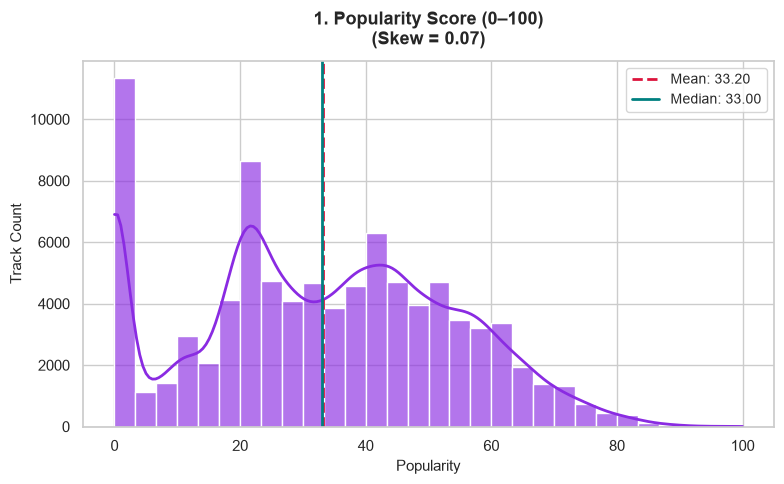

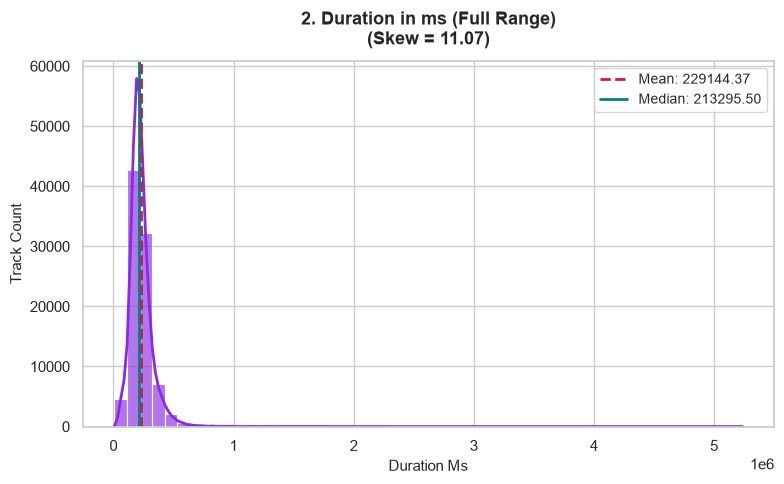

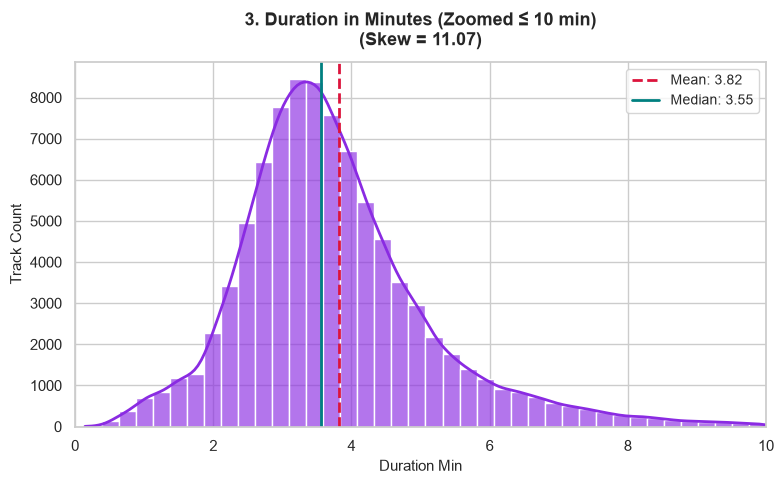

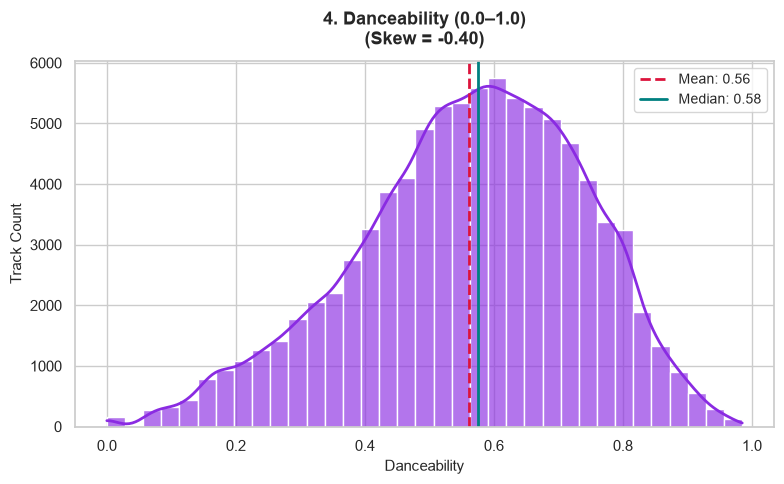

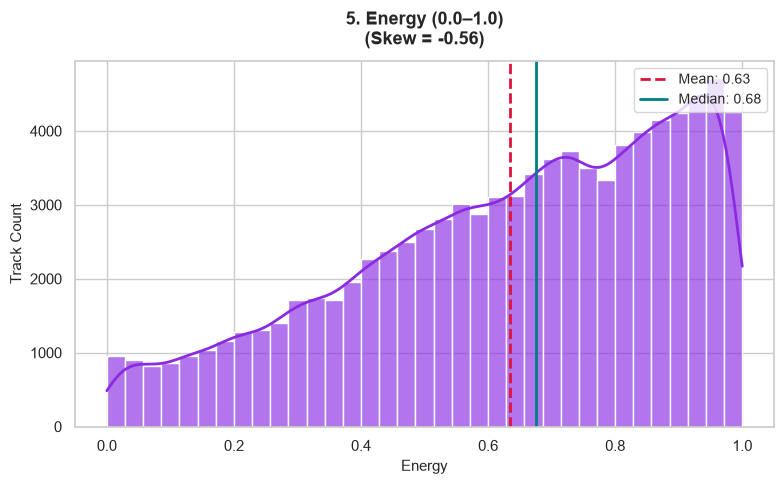

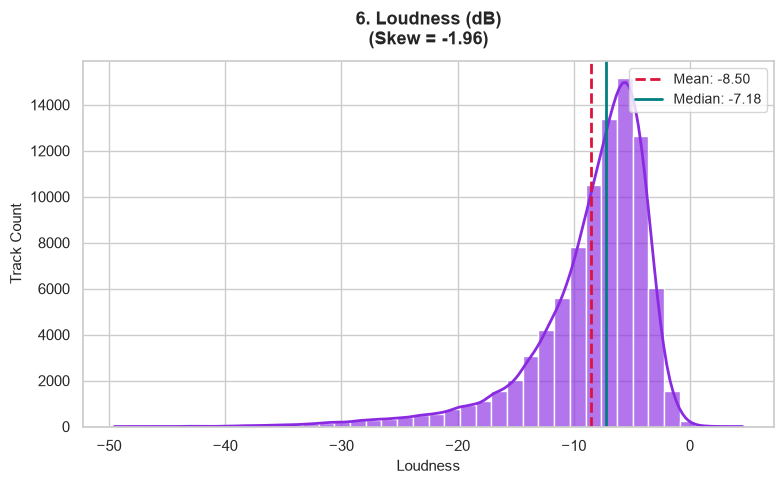

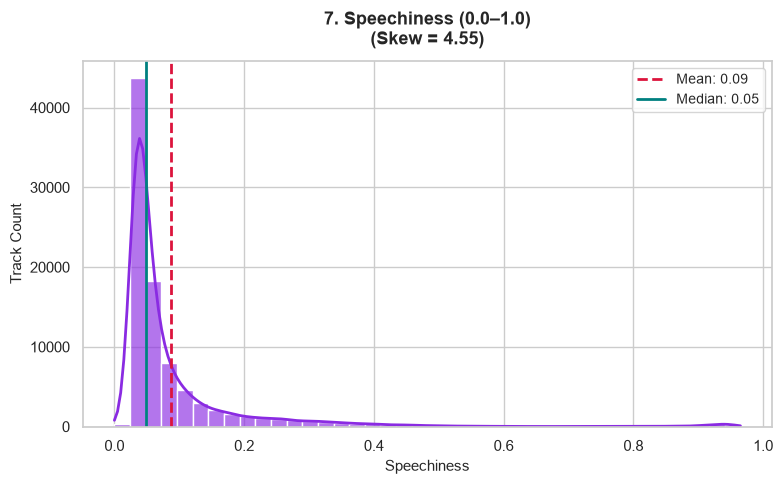

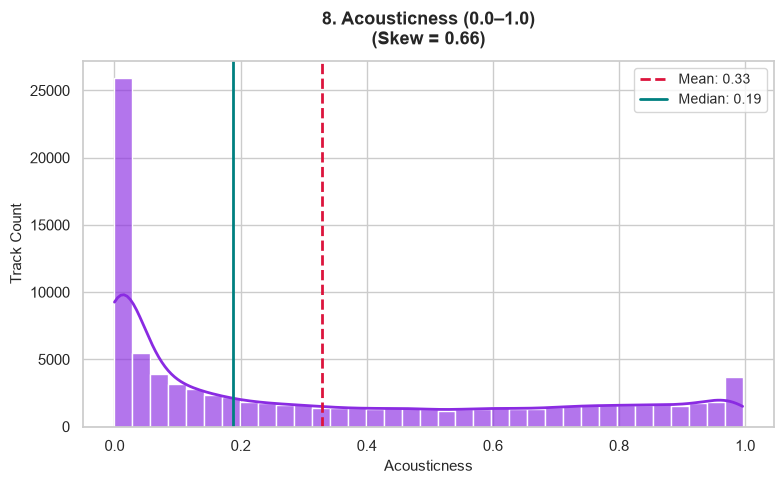

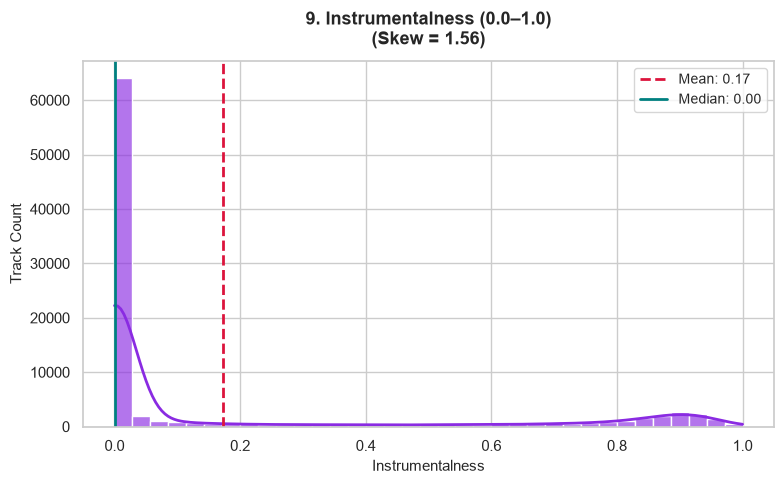

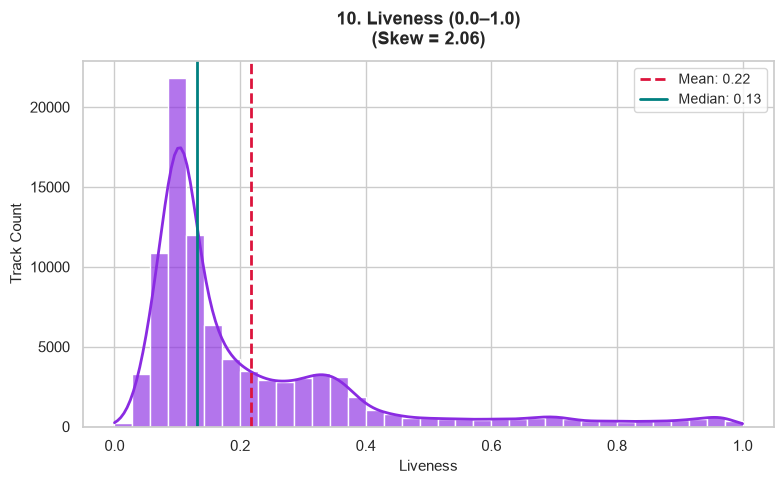

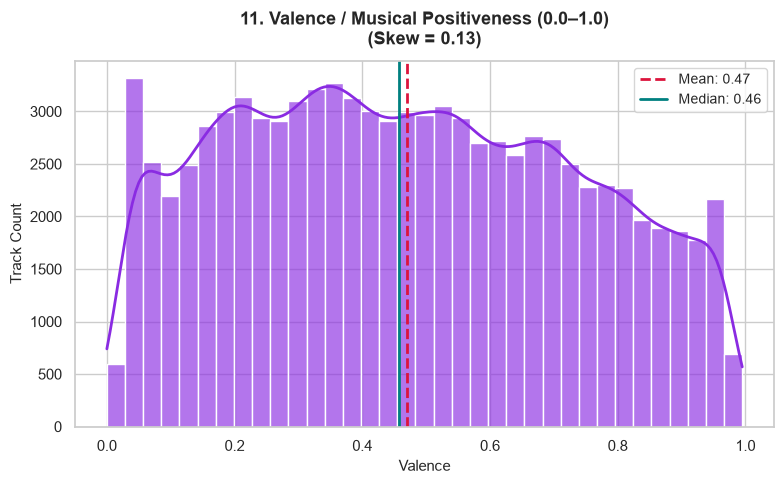

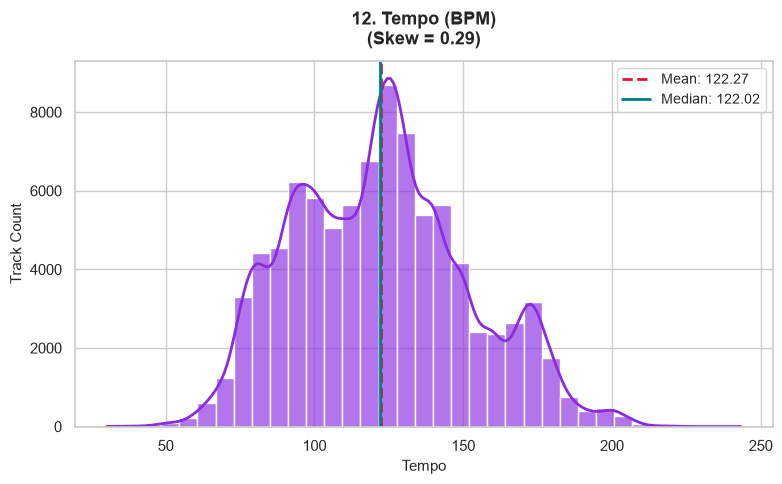

In [65]:
df_unique["duration_min"] = df_unique["duration_ms"] / 60_000.0

# (column, title, bins, optional x-limits)
hist_specs = [
    ("popularity",       "1. Popularity Score (0–100)",                 30, None),
    ("duration_ms",      "2. Duration in ms (Full Range)",              50, None),
    ("duration_min",     "3. Duration in Minutes (Zoomed ≤ 10 min)",    40, (0, 10)),
    ("danceability",     "4. Danceability (0.0–1.0)",                   35, None),
    ("energy",           "5. Energy (0.0–1.0)",                         35, None),
    ("loudness",         "6. Loudness (dB)",                            40, None),
    ("speechiness",      "7. Speechiness (0.0–1.0)",                    40, None),
    ("acousticness",     "8. Acousticness (0.0–1.0)",                   35, None),
    ("instrumentalness", "9. Instrumentalness (0.0–1.0)",               35, None),
    ("liveness",         "10. Liveness (0.0–1.0)",                      35, None),
    ("valence",          "11. Valence / Musical Positiveness (0.0–1.0)", 35, None),
    ("tempo",            "12. Tempo (BPM)",                             35, None),
]

for idx, (col, title, bins, xlim) in enumerate(hist_specs, start=1):
    fig, ax = plt.subplots(figsize=(8, 5))
    
    series = df_unique[col].dropna()
    plot_data = series[(series >= xlim[0]) & (series <= xlim[1])] if xlim else series

    sns.histplot(
        plot_data, 
        bins=bins, 
        kde=True, 
        ax=ax, 
        color=PRIMARY,
        edgecolor="white", 
        alpha=0.65, 
        line_kws={"linewidth": 2, "color": "#4B0082"}
    )
    
    ax.axvline(series.mean(),   color="#DC143C", linestyle="--", linewidth=2, label=f"Mean: {series.mean():.2f}")
    ax.axvline(series.median(), color="#008080", linestyle="-",  linewidth=2, label=f"Median: {series.median():.2f}")

    if xlim:
        ax.set_xlim(xlim)
        
    ax.set_title(f"{title}\n(Skew = {series.skew():.2f})", fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel(col.replace("_", " ").title(), fontsize=11)
    ax.set_ylabel("Track Count", fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=True)

    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"eda_hist_{idx:02d}_{col}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

**Observations:**
- `speechiness`, `instrumentalness`, `liveness`, and `acousticness` are heavily skewed, with most tracks near zero and a long tail of high values.
- `danceability`, `energy`, and `valence` are more symmetric, and `loudness` is left-skewed (most tracks are loud, with a tail of very quiet ones).
- `duration_ms` has a very long right tail; the zoomed view (`≤ 10 min`) shows that most songs cluster around 3–4 minutes.

#### Discrete features and grouped popularity
Categorical and discrete features (`key`, `mode`, `time_signature`, `explicit`) are examined with bar charts. Popularity is compared across `explicit` and `mode` using density-normalized histograms so that groups of different sizes remain comparable.

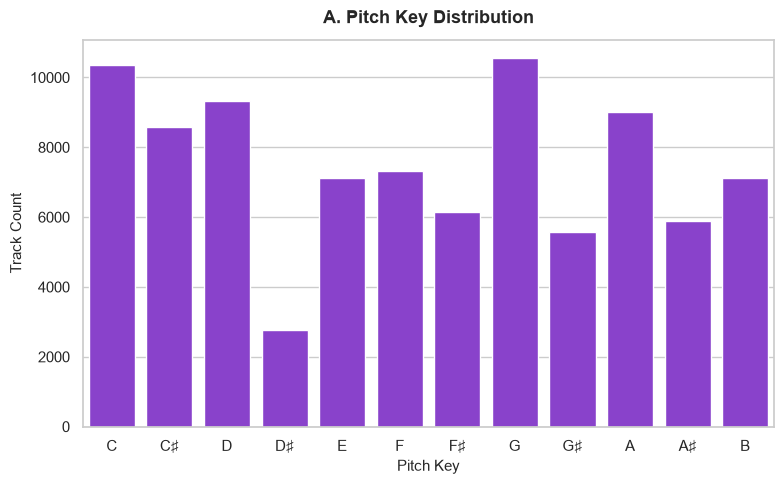

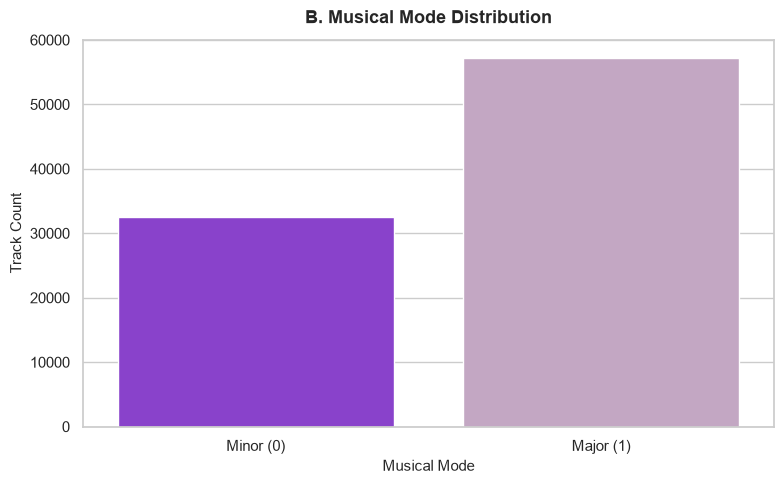

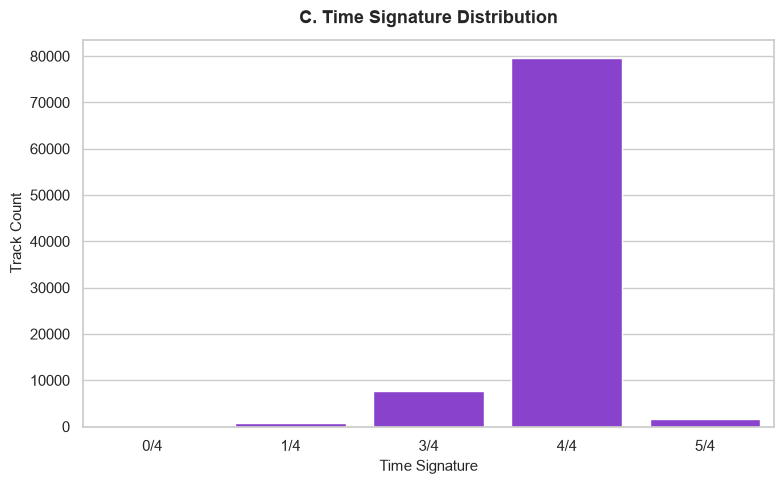

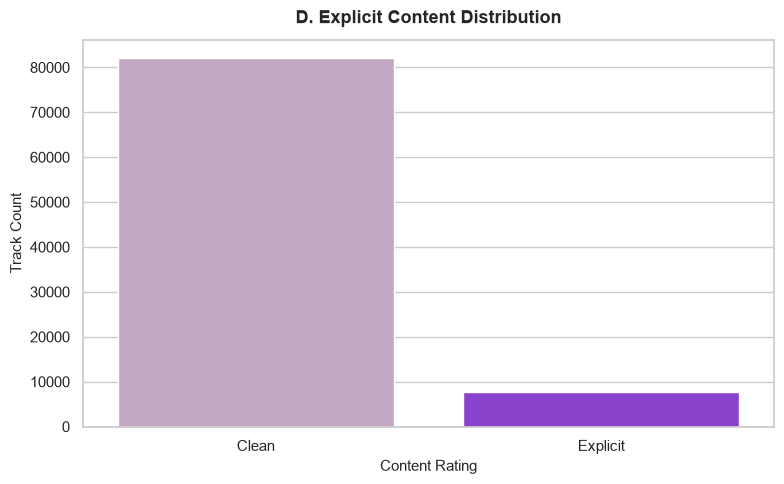

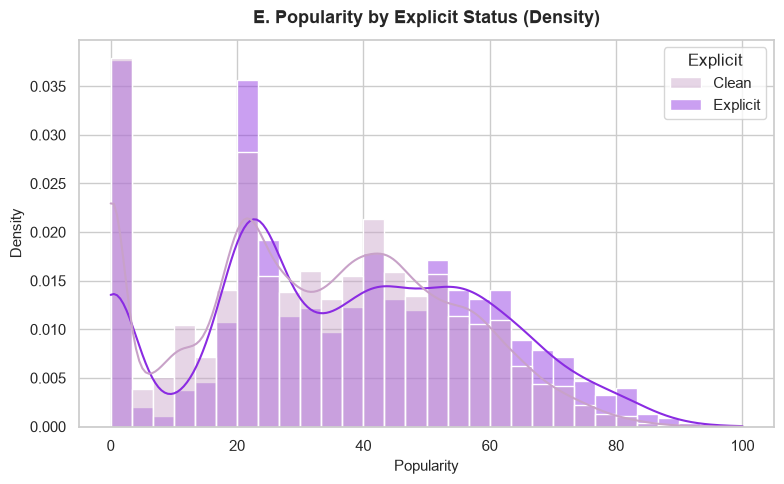

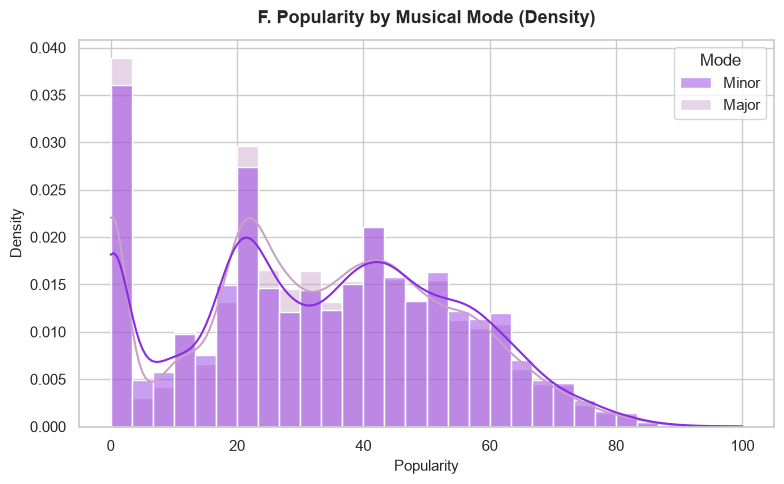

In [66]:
# Prepare data for the discrete and grouped distributions
key_names = ["C", "C♯", "D", "D♯", "E", "F", "F♯", "G", "G♯", "A", "A♯", "B"]
key_counts = df_unique["key"].value_counts().sort_index()
mode_counts = df_unique["mode"].value_counts().sort_index()
ts_counts = df_unique["time_signature"].value_counts().sort_index()
exp_counts = df_unique["explicit"].value_counts().sort_index()

plot_cat = df_unique[["popularity", "explicit", "mode"]].copy()
plot_cat["Explicit"] = plot_cat["explicit"].map({False: "Clean", True: "Explicit"})
plot_cat["Mode"]     = plot_cat["mode"].map({0: "Minor", 1: "Major"})

# Define specifications for all 6 plots
plot_specs = [
    {
        "filename": "eda_discrete_A_key.png",
        "title": "A. Pitch Key Distribution",
        "xlabel": "Pitch Key",
        "ylabel": "Track Count",
        "type": "bar",
        "kwargs": {
            "x": key_names,
            "y": key_counts.values,
            "color": PRIMARY
        }
    },
    {
        "filename": "eda_discrete_B_mode.png",
        "title": "B. Musical Mode Distribution",
        "xlabel": "Musical Mode",
        "ylabel": "Track Count",
        "type": "bar",
        "kwargs": {
            "x": ["Minor (0)", "Major (1)"],
            "y": mode_counts.values,
            "palette": [PRIMARY, SECONDARY],
            "hue": ["Minor (0)", "Major (1)"],
            "legend": False
        }
    },
    {
        "filename": "eda_discrete_C_time_signature.png",
        "title": "C. Time Signature Distribution",
        "xlabel": "Time Signature",
        "ylabel": "Track Count",
        "type": "bar",
        "kwargs": {
            "x": [f"{k}/4" for k in ts_counts.index],
            "y": ts_counts.values,
            "color": PRIMARY
        }
    },
    {
        "filename": "eda_discrete_D_explicit.png",
        "title": "D. Explicit Content Distribution",
        "xlabel": "Content Rating",
        "ylabel": "Track Count",
        "type": "bar",
        "kwargs": {
            "x": ["Clean", "Explicit"],
            "y": exp_counts.values,
            "palette": [SECONDARY, PRIMARY],
            "hue": ["Clean", "Explicit"],
            "legend": False
        }
    },
    {
        "filename": "eda_grouped_E_popularity_explicit.png",
        "title": "E. Popularity by Explicit Status (Density)",
        "xlabel": "Popularity",
        "ylabel": "Density",
        "type": "hist",
        "kwargs": {
            "data": plot_cat,
            "x": "popularity",
            "hue": "Explicit",
            "bins": 30,
            "stat": "density",
            "common_norm": False,
            "kde": True,
            "alpha": 0.45,
            "palette": {"Clean": SECONDARY, "Explicit": PRIMARY}
        }
    },
    {
        "filename": "eda_grouped_F_popularity_mode.png",
        "title": "F. Popularity by Musical Mode (Density)",
        "xlabel": "Popularity",
        "ylabel": "Density",
        "type": "hist",
        "kwargs": {
            "data": plot_cat,
            "x": "popularity",
            "hue": "Mode",
            "bins": 30,
            "stat": "density",
            "common_norm": False,
            "kde": True,
            "alpha": 0.45,
            "palette": {"Minor": PRIMARY, "Major": SECONDARY}
        }
    }
]

# Loop through and render/save each plot individually
for spec in plot_specs:
    fig, ax = plt.subplots(figsize=(8, 5))
    
    if spec["type"] == "bar":
        sns.barplot(ax=ax, **spec["kwargs"])
    elif spec["type"] == "hist":
        sns.histplot(ax=ax, **spec["kwargs"])
        
    ax.set_title(spec["title"], fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel(spec["xlabel"], fontsize=11)
    ax.set_ylabel(spec["ylabel"], fontsize=11)
    
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / spec["filename"], dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

**Observations:**
- The dataset is dominated by **major-mode** tracks (~64%), **4/4 time** and **clean (non-explicit)** content.
- Keys are fairly evenly spread, with G, C, and D the most common.
- The popularity distributions for explicit vs. clean and major vs. minor tracks overlap heavily, which suggests these attributes carry little signal on their own. The numeric checks below confirm this.

### 4.2 Audio Features vs. Popularity

#### Mean popularity by mode and explicit status

In [67]:
df_unique.groupby("mode")["popularity"].agg(["mean", "count"]).rename(index={0: "Minor (0)", 1: "Major (1)"})

,mean,count
mode,,
Minor (0),33.641476,32578
Major (1),32.946520,57162


In [68]:
df_unique.groupby("explicit")["popularity"].agg(["mean", "count"])

,mean,count
explicit,,
False,32.852577,82036
True,36.885644,7704


Major and minor tracks differ by under 1 point in mean popularity (33.6 vs. 32.9), so **mode is effectively irrelevant**. Explicit tracks are about 4 points more popular on average (36.9 vs. 32.9), a small but visible effect.

#### Correlation of key audio features with popularity
Pearson correlation measures the *linear* relationship between each audio feature and popularity.

In [69]:
audio_cols = ["danceability", "energy", "valence", "tempo", "loudness", "acousticness"]
corr_values = (
    df_unique[["popularity"] + audio_cols]
    .corr()["popularity"]
    .drop("popularity")
    .sort_values()
)
corr_values.round(4)

acousticness   -0.0388
valence        -0.0115
tempo           0.0088
energy          0.0137
danceability    0.0643
loudness        0.0717
Name: popularity, dtype: float64

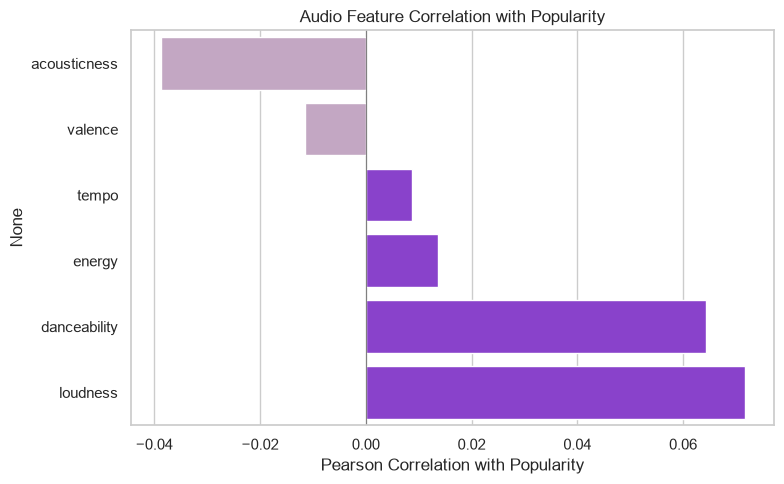

In [70]:
fig, ax = plt.subplots(figsize=(8, 5))
bar_colors = {name: (SECONDARY if v < 0 else PRIMARY) for name, v in corr_values.items()}
sns.barplot(x=corr_values.values, y=corr_values.index, hue=corr_values.index,
            palette=bar_colors, legend=False, ax=ax)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Pearson Correlation with Popularity")
ax.set_title("Audio Feature Correlation with Popularity")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "feature_correlations.png", dpi=150)
plt.show()

**Finding:** every individual audio feature shows a **weak correlation with popularity (|r| < 0.1)**. The strongest are `loudness` (+0.07) and `danceability` (+0.06). Audio characteristics on their own do not explain popularity.

#### Covariance, Pearson and Spearman correlation
To make sure the weak result is not an artefact of assuming a linear relationship, we compare **Pearson** (linear) with **Spearman** (rank-based, robust to outliers and monotonic non-linear trends). If both agree that the relationship is weak, the conclusion is much more reliable.

In [71]:
continuous_cols = [
    "popularity", "duration_ms", "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo",
]

cov_matrix    = df_unique[continuous_cols].cov()
pearson_corr  = df_unique[continuous_cols].corr(method="pearson")
spearman_corr = df_unique[continuous_cols].corr(method="spearman")

print("Covariance with popularity (scale-dependent, shown for completeness)")
display(cov_matrix["popularity"].sort_values(ascending=False).round(4).to_frame("covariance"))

print("Pearson vs. Spearman correlation with popularity")
pop_corr_comparison = pd.DataFrame({
    "Pearson (r)":  pearson_corr["popularity"],
    "Spearman (ρ)": spearman_corr["popularity"],
}).drop("popularity").sort_values("Pearson (r)", ascending=False)
display(pop_corr_comparison.round(4))

Covariance with popularity (scale-dependent, shown for completeness)


,covariance
popularity,423.5628
loudness,7.7022
tempo,5.3773
danceability,0.2337
energy,0.0725
liveness,-0.0556
valence,-0.0623
speechiness,-0.1098
acousticness,-0.2704
instrumentalness,-0.8496


Pearson vs. Spearman correlation with popularity


,Pearson (r),Spearman (ρ)
loudness,0.0717,0.0672
danceability,0.0643,0.0553
energy,0.0137,-0.0157
tempo,0.0088,0.0090
valence,-0.0115,-0.0107
liveness,-0.0139,-0.0115
duration_ms,-0.0232,0.0128
acousticness,-0.0388,0.0103
speechiness,-0.0471,-0.0671
instrumentalness,-0.1275,-0.1244


> **Note on covariance:** covariance depends on the scale of each variable (e.g. `duration_ms` is in the hundreds of thousands, `danceability` is between 0 and 1), so covariance values **cannot be compared across features**. Correlation is the appropriate measure for ranking relationships.

Pearson and Spearman agree on the overall picture: no audio feature has a strong monotonic or linear relationship with popularity.

#### Heatmaps
The heatmaps show the full correlation structure, which highlights relationships *between* features (useful for spotting redundancy) in addition to their relationship with popularity.

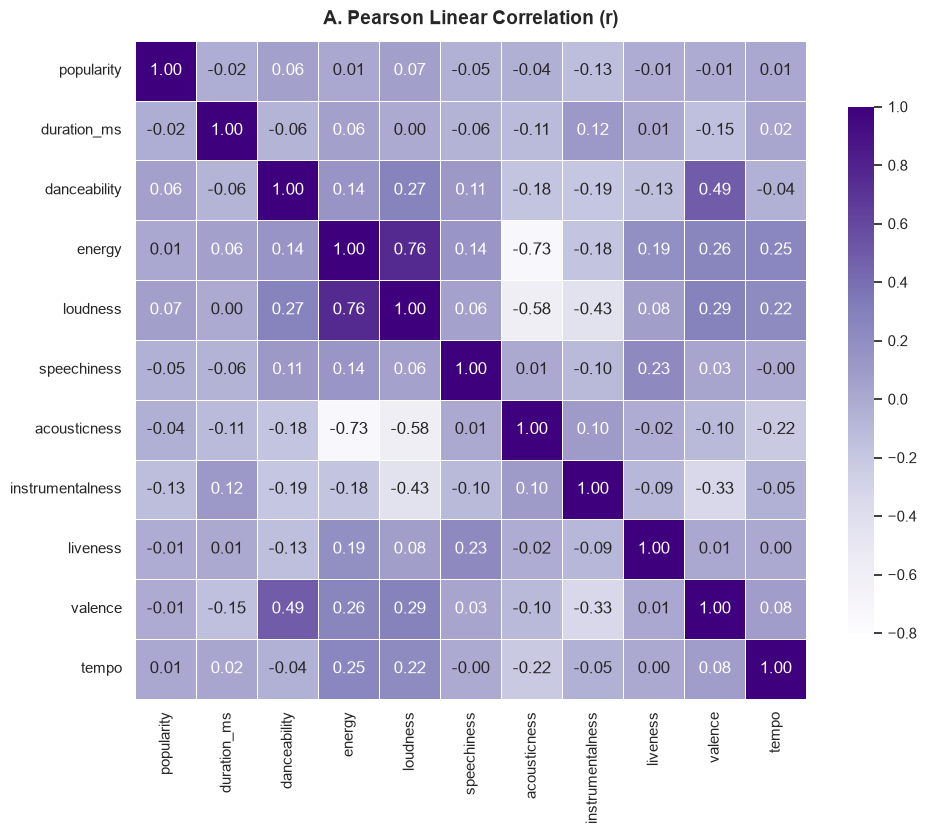

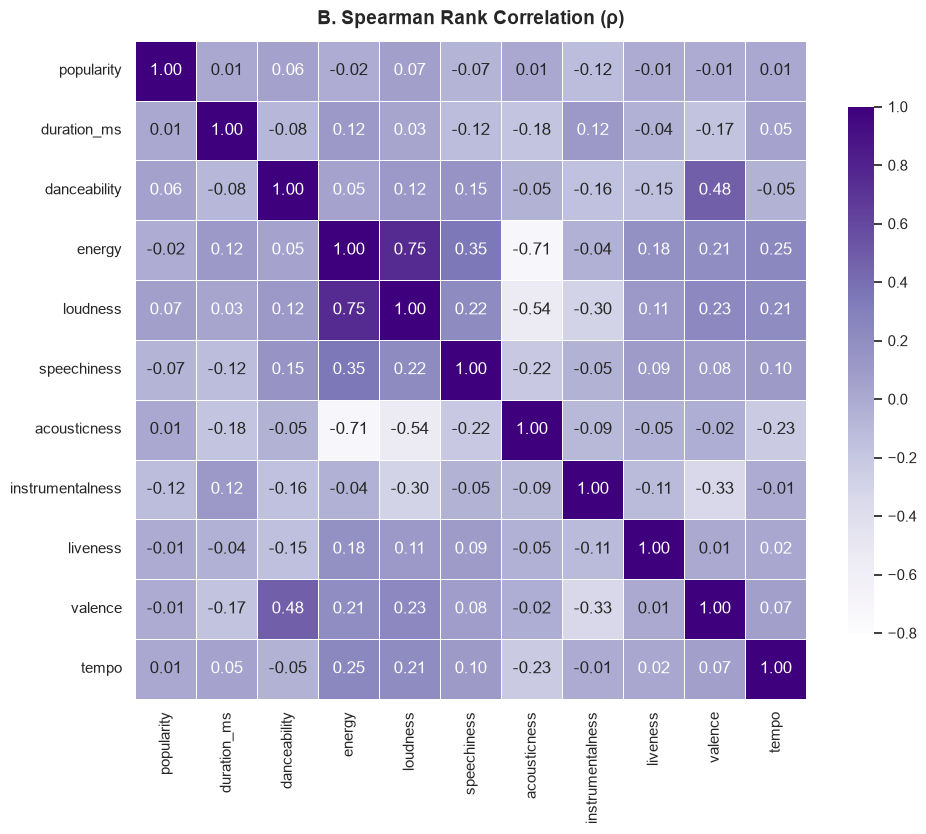

In [72]:
heatmap_specs = [
    (pearson_corr,  "A. Pearson Linear Correlation (r)", "eda_correlation_pearson.png"),
    (spearman_corr, "B. Spearman Rank Correlation (ρ)",  "eda_correlation_spearman.png"),
]

for corr_matrix, title, filename in heatmap_specs:
    fig, ax = plt.subplots(figsize=(10, 8.5))
    
    sns.heatmap(
        corr_matrix, 
        annot=True, 
        fmt=".2f", 
        cmap="Purples", 
        vmin=-0.8, 
        vmax=1.0,
        linewidths=0.5, 
        ax=ax, 
        cbar_kws={"shrink": 0.8}
    )
    
    ax.set_title(title, fontsize=14, fontweight="bold", pad=12)
    
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

**Observations:**
- The strongest relationships are **between audio features**, not with popularity: `energy` and `loudness` are strongly positively correlated, and `acousticness` is strongly negatively correlated with both. These features partly encode the same underlying information (multicollinearity), which matters for interpreting linear models.
- The popularity row/column is uniformly pale, which confirms the weak link seen earlier.

#### Scatter plots with regression lines
A random sample of 2,500 tracks is used to keep the plots legible. The top row shows relationships *between* features; the bottom row includes two that involve popularity. The full-dataset Pearson and Spearman coefficients are shown in each title.

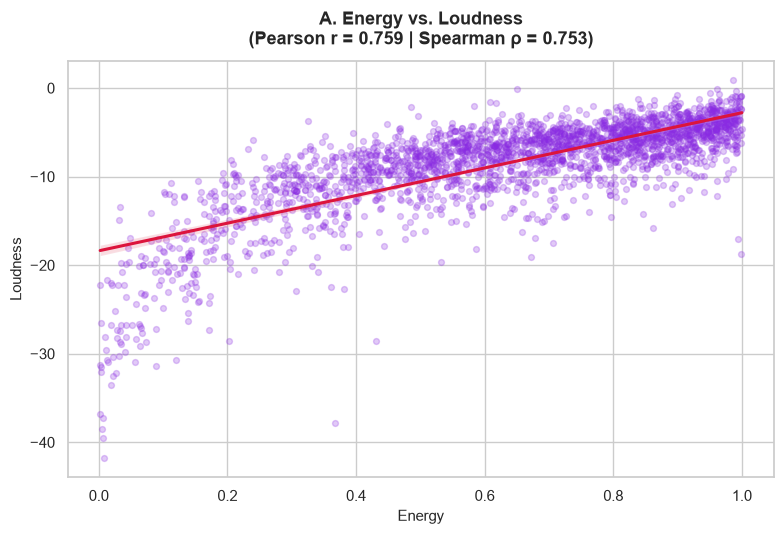

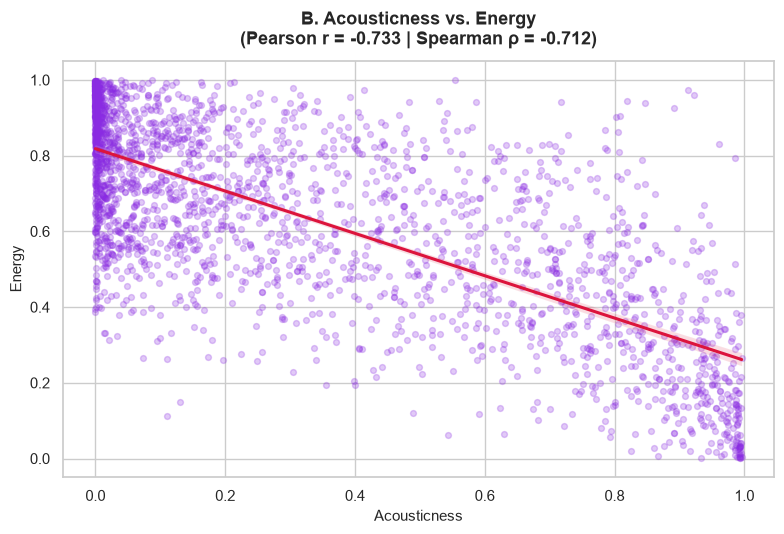

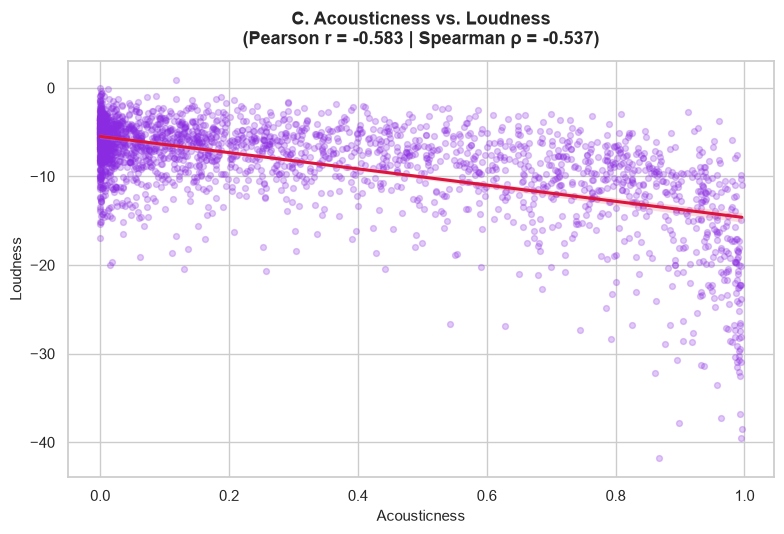

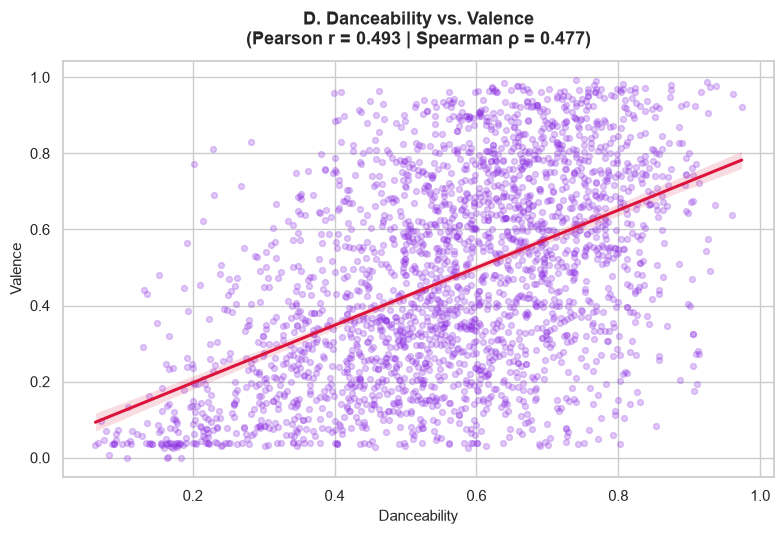

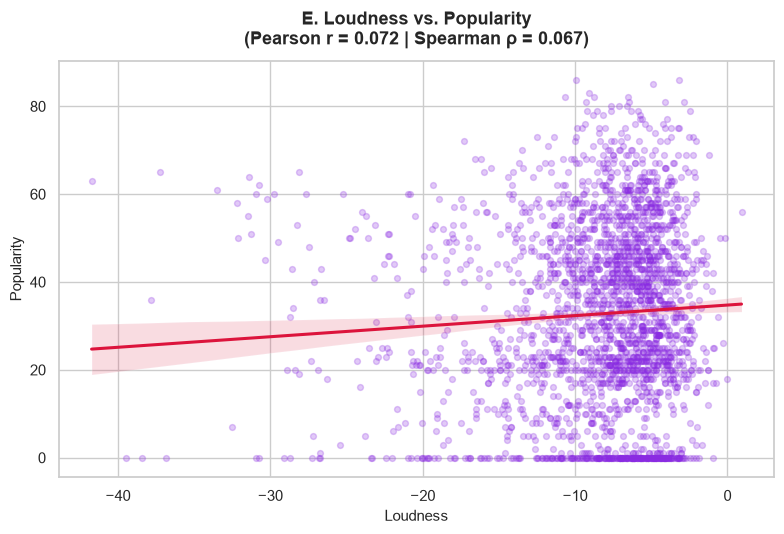

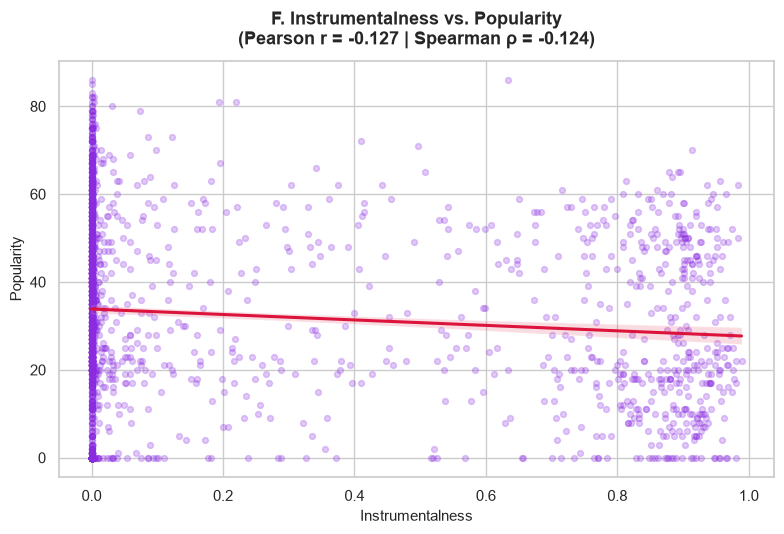

In [73]:
sample_df = df_unique.dropna(subset=["tempo"]).sample(n=2500, random_state=RANDOM_STATE)

scatter_specs = [
    ("energy",           "loudness",   "A. Energy vs. Loudness"),
    ("acousticness",     "energy",     "B. Acousticness vs. Energy"),
    ("acousticness",     "loudness",   "C. Acousticness vs. Loudness"),
    ("danceability",     "valence",    "D. Danceability vs. Valence"),
    ("loudness",         "popularity", "E. Loudness vs. Popularity"),
    ("instrumentalness", "popularity", "F. Instrumentalness vs. Popularity"),
]

for idx, (x_col, y_col, title) in enumerate(scatter_specs, start=1):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    
    sns.regplot(
        data=sample_df, 
        x=x_col, 
        y=y_col, 
        ax=ax,
        scatter_kws={"alpha": 0.25, "color": PRIMARY, "s": 18},
        line_kws={"color": "#DC143C", "linewidth": 2.2}
    )
    
    r = pearson_corr.loc[x_col, y_col]
    s = spearman_corr.loc[x_col, y_col]
    
    ax.set_title(
        f"{title}\n(Pearson r = {r:.3f} | Spearman ρ = {s:.3f})", 
        fontsize=13, 
        fontweight="bold", 
        pad=12
    )
    ax.set_xlabel(x_col.replace("_", " ").title(), fontsize=11)
    ax.set_ylabel(y_col.replace("_", " ").title(), fontsize=11)
    
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"eda_scatter_{idx:02d}_{x_col}_vs_{y_col}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

**Observations:** panels A–C show clear structure (louder tracks are more energetic; acoustic tracks are quieter and less energetic), whereas the popularity panels (E, F) are diffuse clouds with nearly flat regression lines. `instrumentalness` is the only feature with a noticeably negative association (r ≈ −0.13): purely instrumental tracks tend to be less popular.

### 4.3 Distributions Across Categories (Boxplots)
Boxplots summarize the median, spread, and outliers of each group. Panel A shows the distributions of the bounded `[0, 1]` audio features; panels B–D compare popularity across categorical groups.

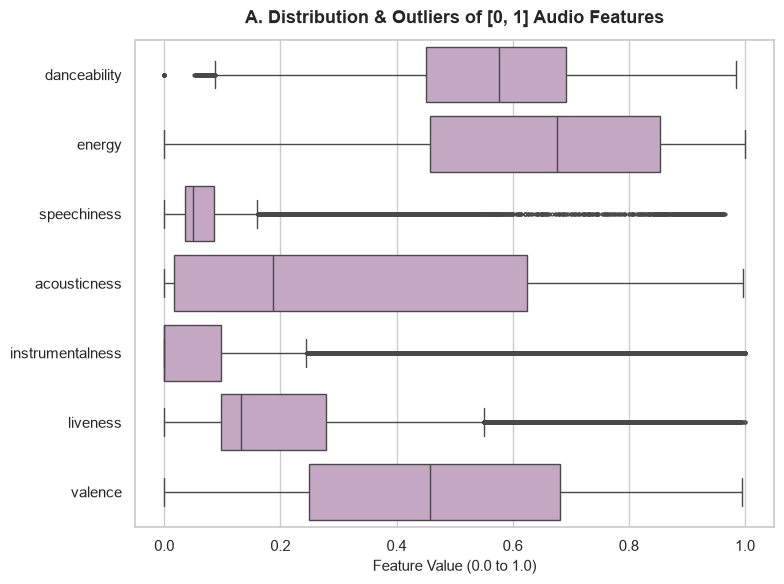

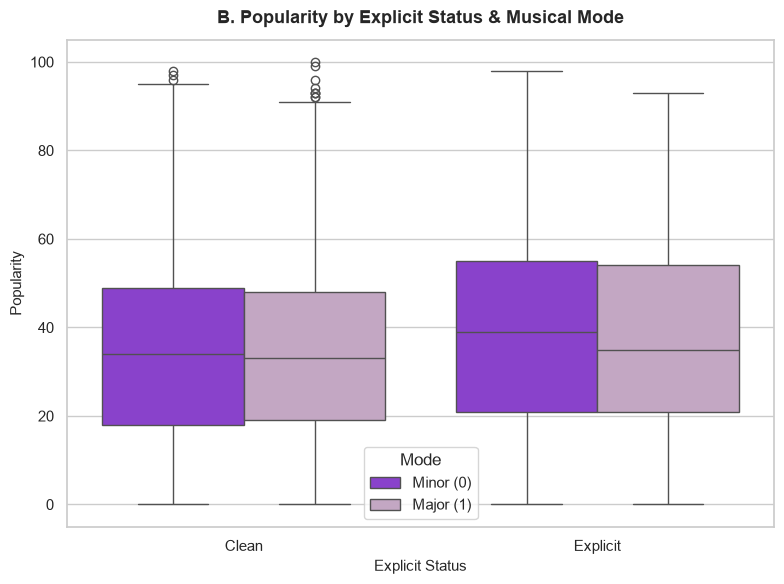

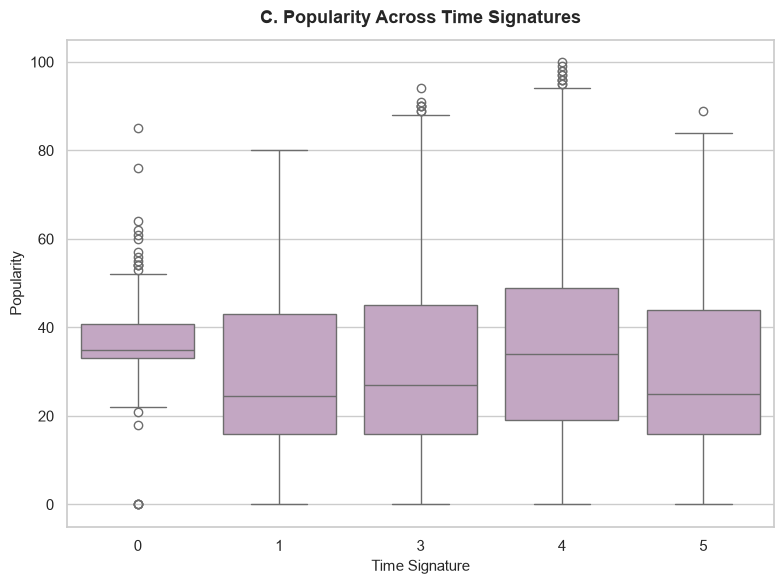

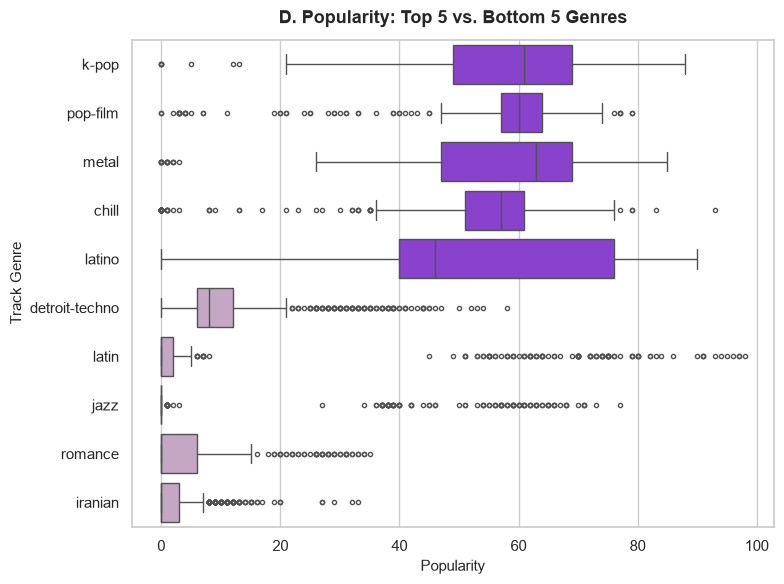

In [74]:
# Prepare data for each boxplot
unit_features = [
    "danceability", "energy", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence"
]

cat_plot = df_unique[["popularity", "explicit", "mode"]].copy()
cat_plot["Explicit"] = cat_plot["explicit"].map({False: "Clean", True: "Explicit"})
cat_plot["Mode"]     = cat_plot["mode"].map({0: "Minor (0)", 1: "Major (1)"})

genre_order = df_unique.groupby("track_genre")["popularity"].mean().sort_values(ascending=False)
selected = genre_order.head(5).index.tolist() + genre_order.tail(5).index.tolist()
genre_palette = {g: (PRIMARY if i < 5 else SECONDARY) for i, g in enumerate(selected)}

# Define specifications for all 4 boxplots
boxplot_specs = [
    {
        "filename": "eda_boxplot_A_audio_features.png",
        "title": "A. Distribution & Outliers of [0, 1] Audio Features",
        "xlabel": "Feature Value (0.0 to 1.0)",
        "ylabel": None,
        "kwargs": {
            "data": df_unique[unit_features],
            "orient": "h",
            "color": SECONDARY,
            "fliersize": 2
        }
    },
    {
        "filename": "eda_boxplot_B_popularity_explicit_mode.png",
        "title": "B. Popularity by Explicit Status & Musical Mode",
        "xlabel": "Explicit Status",
        "ylabel": "Popularity",
        "kwargs": {
            "data": cat_plot,
            "x": "Explicit",
            "y": "popularity",
            "hue": "Mode",
            "palette": [PRIMARY, SECONDARY]
        }
    },
    {
        "filename": "eda_boxplot_C_popularity_time_signature.png",
        "title": "C. Popularity Across Time Signatures",
        "xlabel": "Time Signature",
        "ylabel": "Popularity",
        "kwargs": {
            "data": df_unique,
            "x": "time_signature",
            "y": "popularity",
            "hue": "time_signature",
            "palette": [SECONDARY] * df_unique["time_signature"].nunique(),
            "legend": False
        }
    },
    {
        "filename": "eda_boxplot_D_popularity_top_bottom_genres.png",
        "title": "D. Popularity: Top 5 vs. Bottom 5 Genres",
        "xlabel": "Popularity",
        "ylabel": "Track Genre",
        "kwargs": {
            "data": df_unique[df_unique["track_genre"].isin(selected)],
            "x": "popularity",
            "y": "track_genre",
            "order": selected,
            "hue": "track_genre",
            "palette": genre_palette,
            "legend": False,
            "fliersize": 3
        }
    }
]

# Loop through and render/save each boxplot individually
for spec in boxplot_specs:
    fig, ax = plt.subplots(figsize=(8, 6))
    
    sns.boxplot(ax=ax, **spec["kwargs"])
    
    ax.set_title(spec["title"], fontsize=13, fontweight="bold", pad=12)
    if spec["xlabel"]:
        ax.set_xlabel(spec["xlabel"], fontsize=11)
    if spec["ylabel"]:
        ax.set_ylabel(spec["ylabel"], fontsize=11)
        
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / spec["filename"], dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

**Observations:**
- **A:** many features have numerous high-value outliers (especially `speechiness`, `liveness`, `instrumentalness`). These are valid values rather than errors, so they are left untouched.
- **B & C:** medians barely move between explicit/mode groups or across time signatures, so these variables offer little predictive signal.
- **D:** by contrast, the top and bottom genres occupy almost **completely different** parts of the popularity scale. This is the first strong signal in the analysis, and it is examined next.

### 4.4 Genre as an Explanatory Factor
Since individual audio features were weak, we test whether **genre** explains more of the variation. We compute the mean popularity per genre across the 113 genres in the dataset.

In [75]:
genre_pop = df_unique.groupby("track_genre")["popularity"].mean().sort_values(ascending=False)

print(f"Number of genres : {genre_pop.size}")
print(f"Highest          : {genre_pop.idxmax()} ({genre_pop.max():.1f})")
print(f"Lowest           : {genre_pop.idxmin()} ({genre_pop.min():.1f})")
print(f"Spread (max-min) : {genre_pop.max() - genre_pop.min():.1f} points")

print("\nTop 10 genres")
display(genre_pop.head(10).round(2).to_frame("mean_popularity"))
print("Bottom 10 genres")
display(genre_pop.tail(10).round(2).to_frame("mean_popularity"))

Number of genres : 113
Highest          : k-pop (59.4)
Lowest           : iranian (2.2)
Spread (max-min) : 57.2 points

Top 10 genres


,mean_popularity
track_genre,
k-pop,59.42
pop-film,59.10
metal,56.42
chill,53.74
latino,51.79
sad,51.11
grunge,50.59
indian,49.77
anime,48.78


Bottom 10 genres


,mean_popularity
track_genre,
idm,15.52
kids,14.77
grindcore,14.52
classical,13.36
chicago-house,12.33
detroit-techno,11.13
latin,9.86
jazz,9.79
romance,3.55


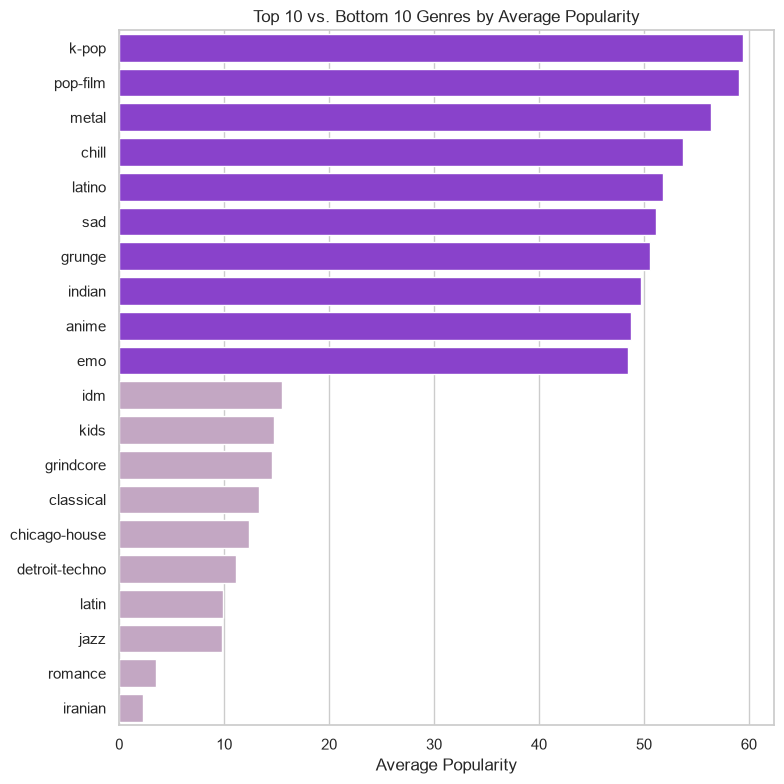

In [76]:
combined = pd.concat([genre_pop.head(10), genre_pop.tail(10)])
genre_colors = {g: (PRIMARY if i < 10 else SECONDARY) for i, g in enumerate(combined.index)}

fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(x=combined.values, y=combined.index, hue=combined.index,
            palette=genre_colors, legend=False, ax=ax)
ax.set_xlabel("Average Popularity")
ax.set_ylabel("")
ax.set_title("Top 10 vs. Bottom 10 Genres by Average Popularity")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "genre_popularity.png", dpi=150)
plt.show()

**Finding:** average genre popularity ranges from about **59** (k-pop, pop-film) down to about **2** (iranian), a spread of roughly **57 points**, which dwarfs the effect of every audio feature tested (correlations below 0.1). **Genre is clearly the dominant factor.**

This motivates the modeling strategy: if genre carries most of the signal, a model that includes it should substantially outperform one that uses audio features alone.

## 5. Modeling

### 5.1 Strategy
Models are built incrementally so that the contribution of each addition can be measured:

| # | Model | Purpose |
|---|---|---|
| 1 | Mean predictor | Naive baseline (R² ≈ 0 by definition) |
| 2 | Linear Regression, **audio features only** | Tests whether audio alone predicts popularity |
| 3 | Linear Regression, **audio + genre** | Measures the added value of genre |
| 4 | Random Forest, **audio + genre** | Tests whether non-linear patterns add further value |

All models are evaluated on the same held-out test set using **R²**, **MAE** (mean absolute error, in popularity points) and **RMSE**.

### 5.2 Feature Selection and Train/Test Split
Seven audio features are used. `track_genre` is added separately as an encoded feature. Rows with a missing `tempo` (the 157 tracks from Section 3.3) are excluded here. The data is split **80% / 20%** with a fixed random seed for reproducibility.

In [77]:
AUDIO_FEATURES = ["danceability", "energy", "loudness", "valence",
                  "tempo", "acousticness", "speechiness"]

X = df_unique[AUDIO_FEATURES + ["track_genre"]].dropna()
y = df_unique.loc[X.index, "popularity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
X_train, X_test = X_train.copy(), X_test.copy()

print(f"Training set: {len(X_train):,} rows")
print(f"Test set    : {len(X_test):,} rows")

Training set: 71,666 rows
Test set    : 17,917 rows


### 5.3 Genre Encoding (Target Mean Encoding)
`track_genre` has 113 categories, so one-hot encoding would add 113 sparse columns. Instead, each genre is replaced by its **mean popularity**.

> 🔒 **Avoiding data leakage:** the genre means are computed from the **training set only** (`y_train`) and then applied to both the training and test sets. Computing them on the full dataset would leak information about the test targets into the features and inflate the scores.

In [78]:
genre_means = y_train.groupby(X_train["track_genre"]).mean()

X_train["genre_encoded"] = X_train["track_genre"].map(genre_means)
X_test["genre_encoded"]  = X_test["track_genre"].map(genre_means)

MODEL_FEATURES = AUDIO_FEATURES + ["genre_encoded"]

print(f"Unseen genres in test set: {X_test['genre_encoded'].isna().sum()}")

Unseen genres in test set: 0


### 5.4 Model Training and Evaluation
A small helper function computes the same three metrics for every model so that the comparison is consistent.

In [79]:
def evaluate(name, y_true, y_pred):
    # Return R², MAE and RMSE for a set of predictions.
    return {
        "Model": name,
        "R²":    r2_score(y_true, y_pred),
        "MAE":   mean_absolute_error(y_true, y_pred),
        "RMSE":  np.sqrt(mean_squared_error(y_true, y_pred)),
    }

results = []

# 1. Naive baseline: always predict the training mean
baseline_pred = np.full(len(y_test), y_train.mean())
results.append(evaluate("Mean predictor (baseline)", y_test, baseline_pred))

# 2. Linear Regression: audio features only
lr_audio = LinearRegression().fit(X_train[AUDIO_FEATURES], y_train)
results.append(evaluate("Linear Regression (audio only)", y_test, lr_audio.predict(X_test[AUDIO_FEATURES])))

# 3. Linear Regression: audio + genre
lr_genre = LinearRegression().fit(X_train[MODEL_FEATURES], y_train)
results.append(evaluate("Linear Regression (audio + genre)", y_test, lr_genre.predict(X_test[MODEL_FEATURES])))

In [80]:
# 4. Random Forest: audio + genre
rf_model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train[MODEL_FEATURES], y_train)

rf_predictions = rf_model.predict(X_test[MODEL_FEATURES])
results.append(evaluate("Random Forest (audio + genre)", y_test, rf_predictions))

In [81]:
results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,R²,MAE,RMSE
Model,,,
Mean predictor (baseline),-0.000,17.112,20.436
Linear Regression (audio only),0.017,16.783,20.259
Linear Regression (audio + genre),0.331,11.899,16.721
Random Forest (audio + genre),0.465,10.091,14.952


### 5.5 Results

| Model | R² | Interpretation |
|---|---|---|
| Mean predictor | ≈ 0.00 | Reference point |
| Linear Regression (audio only) | ≈ 0.02 | Audio features alone explain almost nothing |
| Linear Regression (audio + genre) | ≈ 0.33 | Adding genre is a **huge** improvement |
| Random Forest (audio + genre) | ≈ 0.46 | Non-linear patterns add a further gain |

**Takeaways**
- The audio-only linear model explains about **2%** of the variance, only marginally better than guessing the mean. This confirms the weak correlations found in the EDA.
- Adding a single genre feature lifts R² to **0.33**, which confirms genre as the dominant signal.
- The Random Forest reaches **R² = 0.46** and reduces the average error to about **10 popularity points** (down from 17 for the baseline). It captures non-linear interactions (e.g. a feature mattering differently in different genres) that the linear model cannot.
- Even the best model leaves more than half of the variance unexplained, which is expected: popularity also depends on factors absent from this data, such as artist fame, marketing, release timing, and playlist placement.

### 5.6 Feature Importance
Random Forest feature importances show how much each input contributes to the model's splits. Note that importance values sum to 1.

In [82]:
importances = pd.Series(rf_model.feature_importances_, index=MODEL_FEATURES).sort_values(ascending=False)
importances.round(4).to_frame("importance")

,importance
genre_encoded,0.3945
loudness,0.0916
acousticness,0.0900
danceability,0.0871
tempo,0.0860
valence,0.0858
speechiness,0.0841
energy,0.0808


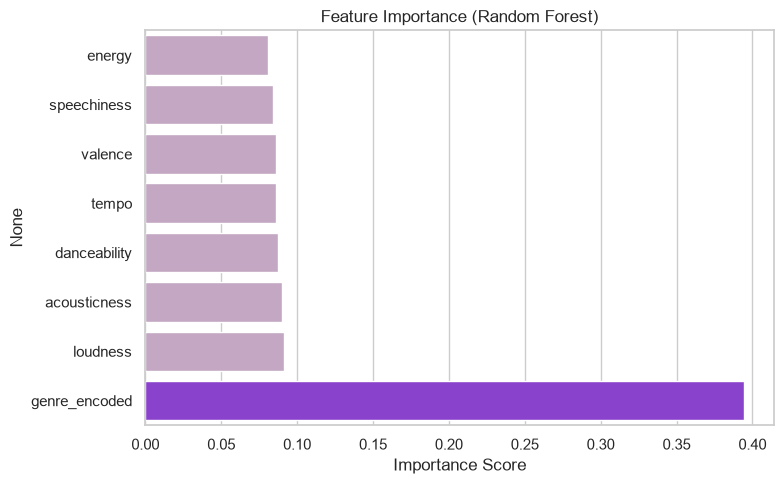

In [83]:
fig, ax = plt.subplots(figsize=(8, 5))
imp_plot = importances.sort_values()
imp_colors = {f: (PRIMARY if f == "genre_encoded" else SECONDARY) for f in imp_plot.index}
sns.barplot(x=imp_plot.values, y=imp_plot.index, hue=imp_plot.index,
            palette=imp_colors, legend=False, ax=ax)
ax.set_xlabel("Importance Score")
ax.set_title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "feature_importance.png", dpi=150)
plt.show()

**Finding:** `genre_encoded` accounts for about **39%** of total importance, more than four times that of any individual audio feature (each roughly 8–9%). The seven audio features contribute nearly equally to one another, consistent with each carrying only a small amount of independent signal.

## 6. Error Analysis

Aggregate metrics show *how often* the model is wrong, but not *why*. To understand failure modes, we examine the **15 largest prediction errors** on the test set. Error is defined as `actual − predicted`, so positive values are under-predictions.

In [84]:
results_test = X_test.copy()
results_test["actual_popularity"]    = y_test
results_test["predicted_popularity"] = rf_predictions
results_test["error"]     = results_test["actual_popularity"] - results_test["predicted_popularity"]
results_test["abs_error"] = results_test["error"].abs()

worst = results_test.sort_values("abs_error", ascending=False).head(15)

worst_report = worst[["track_genre", "actual_popularity", "predicted_popularity", "error"]].join(
    df_unique.loc[worst.index, ["track_name", "artists"]]
)
worst_report[["track_name", "artists", "track_genre", "actual_popularity", "predicted_popularity", "error"]].round(1)

,track_name,artists,track_genre,actual_popularity,predicted_popularity,error
67500,Ojitos Lindos,Bad Bunny;Bomba Estéreo,latin,95,7.9,87.1
20418,The Motto,Tiësto;Ava Max,dance,86,0.0,86.0
20602,Leave The Door Open,Bruno Mars;Anderson .Paak;Silk Sonic,dance,84,0.9,83.1
20026,The Nights,Avicii,dance,86,3.0,83.0
67356,La Bachata,Manuel Turizo,latin,98,17.8,80.2
99046,Victoria’s Secret,Jax,singer-songwriter,82,2.2,79.8
3255,Feel Good Inc.,Gorillaz,alternative,84,5.0,79.0
15017,At My Worst,Pink Sweat$,chill,76,0.2,75.8
68492,Perreito,Mariah Angeliq,latino,0,75.3,-75.3
2312,Bitter Sweet Symphony,The Verve,alt-rock,80,4.8,75.2


**Finding:** the largest errors are almost all **severe under-estimates of cross-genre hits** (e.g. *Gasolina*, *BICHOTA*, *Thunder*). These are mainstream hits that happen to be tagged under a lower-popularity genre. Because de-duplication used `keep="first"` (Section 3.2), the genre tag each song retained was effectively arbitrary, which dragged the genre-based prediction down despite the song being genuinely popular. A smaller number of errors go the other way (a track with popularity 0 in a generally popular genre).

**Takeaway:** this is primarily a **methodology limitation, not a modeling failure.** The model is faithfully reflecting the (noisy) genre label it was given.

**Possible improvement:** encode genre using each song's *highest-popularity* tag, or use **multi-label genre features** (a binary flag per genre) so that a song retains all of its genre information.

## 7. Model Persistence

The trained Random Forest and the genre → mean-popularity mapping are saved with `joblib` so they can be loaded independently by the deployment API (`app.py`) **without retraining**. Both artifacts are required at inference time: the model expects the encoded genre value as input, which is produced by the mapping.

> **Inference reminder:** the API must apply the same `genre_means` lookup to incoming requests and supply features in the order defined by `MODEL_FEATURES`. Genres that are not in the mapping need an explicit fallback (e.g. the global mean popularity).

In [85]:
joblib.dump(rf_model, MODEL_PATH)
joblib.dump(genre_means, GENRE_PATH)

print(f"Saved model         -> {MODEL_PATH}")
print(f"Saved genre mapping -> {GENRE_PATH}")
print(f"Expected feature order: {MODEL_FEATURES}")

Saved model         -> popularity_model.pkl
Saved genre mapping -> genre_means.pkl
Expected feature order: ['danceability', 'energy', 'loudness', 'valence', 'tempo', 'acousticness', 'speechiness', 'genre_encoded']


## 8. Conclusions, Limitations & Next Steps

### Conclusions
1. **Audio features are weak predictors.** No individual feature has a correlation above 0.1 with popularity, and a linear model on audio alone reaches an R² of only ≈ 0.02.
2. **Genre is the dominant factor.** Average popularity varies by ≈ 57 points between genres, and adding genre raises R² from ≈ 0.02 to ≈ 0.33.
3. **Non-linear modeling helps.** A Random Forest reaches R² ≈ 0.46 (MAE ≈ 10 points), and genre alone accounts for ≈ 39% of its feature importance.
4. **Most of popularity remains unexplained** by the available data, which is plausible given that popularity is driven largely by external factors.

### Limitations
- **Arbitrary genre assignment:** `keep="first"` de-duplication discards genre information for multi-genre tracks and causes the largest prediction errors.
- **Target mean encoding** of a 113-level category can overfit rare genres; no cross-validation or smoothing was applied.
- **Popularity is a snapshot** of recent play activity, not a fixed property of a song, and 10% of tracks sit at exactly 0.
- **Single train/test split:** reported metrics come from one split and carry no confidence interval.
- **No artist or temporal information** is available, although both are likely strong predictors.

### Recommended Next Steps
- Replace arbitrary de-duplication with **multi-label genre features** or a "highest-popularity tag" rule.
- Use **k-fold cross-validation** and tune hyperparameters (e.g. `max_depth`, `min_samples_leaf`, `n_estimators`) to improve reliability and reduce over-fitting.
- Try **gradient-boosted trees** (e.g. XGBoost, LightGBM) and compare against the Random Forest.
- Add artist-level features (e.g. artist average popularity) with careful leakage control.
- Consider modeling the **zero-popularity spike** separately (two-stage model: *is it zero?* then *how popular?*).

### Reproducibility
- Run the notebook top-to-bottom with `dataset.csv` in the same directory.
- Random seed: `RANDOM_STATE = 42`. Figures are written to `figures/` and model artifacts to the working directory.